# 📘 Skripsi: Perbandingan Kinerja RoBERTa-base vs DistilBERT-base untuk Deteksi Phishing URL

**Pipeline**: Custom URLBERT Tokenizer → Two-Stage Fine-Tuning → Komparasi Evaluasi

---

## BAGIAN 1: SETUP & PRAPEMROSESAN GLOBAL

### Sel 1 — Mount Google Drive & Instalasi Pustaka

In [1]:
# ============================================================
# Sel 1: Mount Google Drive & Instalasi Pustaka
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

!pip install -q transformers tokenizers datasets scikit-learn pandas accelerate matplotlib seaborn

import torch
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Mounted at /content/drive
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA A100-SXM4-40GB


### Sel 2 — Deklarasi Path, Random Seed, Device & Hyperparameter 1-Stage

In [2]:
# ============================================================
# Sel 2: Deklarasi Path, Random Seed & Device
# ============================================================
import os
import random
import numpy as np
import torch

# --- Variabel Path ---
PROJECT_DIR = '/content/drive/MyDrive/Skripsi'
DATASET_CSV = os.path.join(PROJECT_DIR, 'new data', 'vonDataset_clean.csv')
VOCAB_LOCAL = os.path.join(PROJECT_DIR, 'custom_url_tokenizer', 'vocab.txt')
VOCAB_GIT = os.path.join(PROJECT_DIR, 'custom_url_tokenizer', 'vocab_Git.txt')
VOCAB_MERGED = os.path.join(PROJECT_DIR, 'custom_url_tokenizer', 'vocab_merged.txt')
LOG_FILE = os.path.join(PROJECT_DIR, 'SKRIPSI_LOG.md')
RESULTS_CSV = os.path.join(PROJECT_DIR, 'hasil_komparasi_roberta_vs_distilbert.csv')

# Direktori Penyimpanan Model Permanen
MODELS_DIR = os.path.join(PROJECT_DIR, 'models')
DISTILBERT_SAVE_PATH = os.path.join(MODELS_DIR, 'distilbert_phishing')
ROBERTA_SAVE_PATH = os.path.join(MODELS_DIR, 'roberta_phishing')

# Pastikan sub-folder ada
os.makedirs(os.path.join(PROJECT_DIR, 'custom_url_tokenizer'), exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(os.path.join(PROJECT_DIR, 'results'), exist_ok=True)

# --- Hyperparameter 1-Stage End-to-End Fine-Tuning ---
SEED = 42
MAX_LENGTH = 128
BATCH_SIZE = 32
EPOCHS = 2
LEARNING_RATE = 2e-5
WARMUP_RATIO = 0.1
WEIGHT_DECAY = 0.01

# --- Reproducibility Seed ---
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# --- Device ---
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"DEVICE: {DEVICE}")
print(f"PROJECT_DIR: {PROJECT_DIR}")
print(f"Hyperparameters: SEED={SEED}, MAX_LENGTH={MAX_LENGTH}, BATCH_SIZE={BATCH_SIZE}")
print(f"  1-Stage End-to-End: {EPOCHS} epochs, LR={LEARNING_RATE}, Warmup={WARMUP_RATIO*100:.0f}%, Weight Decay={WEIGHT_DECAY}")


DEVICE: cuda
PROJECT_DIR: /content/drive/MyDrive/Skripsi
Hyperparameters: SEED=42, MAX_LENGTH=128, BATCH_SIZE=32
  1-Stage End-to-End: 2 epochs, LR=2e-05, Warmup=10%, Weight Decay=0.01


### Sel 3 — Logika Penggabungan Kosakata (Vocab Merging)

In [3]:
# ============================================================
# Sel 3: Vocab Merging — Gabungkan vocab.txt & vocab_Git.txt
# ============================================================

# Special tokens URLBERT yang HARUS berada di posisi teratas
SPECIAL_TOKENS = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]", "[REP]", "[SHU]"]

def read_vocab_file(filepath):
    """Baca file vocab, satu token per baris."""
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            token = line.strip()
            if token:
                tokens.append(token)
    return tokens

def merge_vocabularies(vocab_local_path, vocab_git_path, output_path, special_tokens):
    """Gabungkan dua file vocab dengan deduplikasi, special tokens di atas."""
    vocab_local = read_vocab_file(vocab_local_path)
    vocab_git = read_vocab_file(vocab_git_path)

    print(f"Vocab Lokal  : {len(vocab_local):,} token dari {vocab_local_path}")
    print(f"Vocab GitHub : {len(vocab_git):,} token dari {vocab_git_path}")

    # Mulai dengan special tokens
    merged_ordered = list(special_tokens)
    seen = set(special_tokens)

    # Tambahkan token dari vocab_local (urutan asli, skip duplikat)
    for token in vocab_local:
        if token not in seen:
            merged_ordered.append(token)
            seen.add(token)

    # Tambahkan token dari vocab_git (urutan asli, skip duplikat)
    for token in vocab_git:
        if token not in seen:
            merged_ordered.append(token)
            seen.add(token)

    # Simpan ke file
    with open(output_path, 'w', encoding='utf-8') as f:
        for token in merged_ordered:
            f.write(token + '\n')

    print(f"\n--- Ringkasan Statistik Vocab Merging ---")
    print(f"Special Tokens        : {len(special_tokens)}")
    print(f"Token dari Lokal      : {len(vocab_local):,}")
    print(f"Token dari GitHub     : {len(vocab_git):,}")
    print(f"Total Sebelum Dedup   : {len(vocab_local) + len(vocab_git) + len(special_tokens):,}")
    print(f"Total Setelah Dedup   : {len(merged_ordered):,}")
    print(f"Token Duplikat Dihapus: {len(vocab_local) + len(vocab_git) + len(special_tokens) - len(merged_ordered):,}")
    print(f"Disimpan ke           : {output_path}")

    return merged_ordered

merged_vocab = merge_vocabularies(VOCAB_LOCAL, VOCAB_GIT, VOCAB_MERGED, SPECIAL_TOKENS)
print(f"\n5 token pertama : {merged_vocab[:6]}")
print(f"5 token terakhir: {merged_vocab[-5:]}")


Vocab Lokal  : 30,000 token dari /content/drive/MyDrive/Skripsi/custom_url_tokenizer/vocab.txt
Vocab GitHub : 5,000 token dari /content/drive/MyDrive/Skripsi/custom_url_tokenizer/vocab_Git.txt

--- Ringkasan Statistik Vocab Merging ---
Special Tokens        : 7
Token dari Lokal      : 30,000
Token dari GitHub     : 5,000
Total Sebelum Dedup   : 35,007
Total Setelah Dedup   : 30,372
Token Duplikat Dihapus: 4,635
Disimpan ke           : /content/drive/MyDrive/Skripsi/custom_url_tokenizer/vocab_merged.txt

5 token pertama : ['[PAD]', '[UNK]', '[CLS]', '[SEP]', '[MASK]', '[REP]']
5 token terakhir: ['##icol', '##apoi', '20ch', '##idente', '##oportlet']


### Sel 4 — Preprocessing Dataset & Stratified Split

In [4]:
# ============================================================
# Sel 4: Preprocessing Dataset & Stratified Split
# ============================================================
import pandas as pd
import re
from sklearn.model_selection import train_test_split

# --- Load Dataset ---
df = pd.read_csv(DATASET_CSV)
print(f"Dataset asli: {len(df):,} baris, kolom: {df.columns.tolist()}")

# Drop kolom 'split' (WAJIB DIABAIKAN)
if 'split' in df.columns:
    df = df.drop(columns=['split'])
    print("Kolom 'split' berhasil di-drop.")

# Gunakan hanya kolom 'url' dan 'label'
df = df[['url', 'label']].copy()

# Hapus baris NaN/null
before_drop = len(df)
df = df.dropna(subset=['url', 'label'])
print(f"Baris dihapus (NaN): {before_drop - len(df):,}")

# Pastikan tipe label integer biner
df['label'] = df['label'].astype(int)
assert df['label'].isin([0, 1]).all(), "Label harus biner (0 atau 1)!"
print(f"Dataset bersih: {len(df):,} baris")
print(f"Distribusi label:\n{df['label'].value_counts().to_string()}")

# --- Fungsi Preprocessing URL ---
def preprocess_url(url):
    """
    Preprocessing URL:
    1. Lowercasing
    2. Konversi IDN/homoglif ke Punycode (xn--)
    3. Delimiter spacing untuk tokenizer
    """
    if not isinstance(url, str):
        return ''

    # 1. Lowercase
    url = url.lower().strip()

    # 2. Konversi IDN/homoglif ke Punycode
    try:
        # Pisahkan protocol
        if '://' in url:
            protocol, rest = url.split('://', 1)
            # Ambil hostname
            if '/' in rest:
                hostname, path = rest.split('/', 1)
                path = '/' + path
            else:
                hostname = rest
                path = ''
            # Encode hostname ke Punycode jika ada karakter non-ASCII
            try:
                hostname = hostname.encode('idna').decode('ascii')
            except (UnicodeError, UnicodeDecodeError):
                pass  # Biarkan jika gagal
            url = protocol + '://' + hostname + path
    except Exception:
        pass

    # 3. Delimiter spacing — tambah spasi di sekitar delimiter URL
    url = url.replace('://', ' :// ')
    url = url.replace('/', ' / ')
    url = url.replace('?', ' ? ')
    url = url.replace('=', ' = ')
    url = url.replace('&', ' & ')
    url = url.replace('.', ' . ')
    url = url.replace('-', ' - ')

    # Normalisasi whitespace berlebih
    url = re.sub(r'\s+', ' ', url).strip()

    return url

# Terapkan preprocessing
print("\nMenerapkan preprocessing URL...")
df['url'] = df['url'].apply(preprocess_url)

# Contoh hasil preprocessing
print("\nContoh URL setelah preprocessing:")
for i in range(min(3, len(df))):
    print(f"  [{df.iloc[i]['label']}] {df.iloc[i]['url'][:120]}")

# --- Stratified Split: 70% Train, 15% Val, 15% Test ---
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df['label'], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED
)

# Reset index
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"\n--- Stratified Split (70/15/15) ---")
print(f"Train : {len(train_df):,} sampel (label dist: {train_df['label'].value_counts().to_dict()})")
print(f"Val   : {len(val_df):,} sampel (label dist: {val_df['label'].value_counts().to_dict()})")
print(f"Test  : {len(test_df):,} sampel (label dist: {test_df['label'].value_counts().to_dict()})")

Dataset asli: 1,559,362 baris, kolom: ['url', 'label', 'split']
Kolom 'split' berhasil di-drop.
Baris dihapus (NaN): 0
Dataset bersih: 1,559,362 baris
Distribusi label:
label
0    800000
1    759362

Menerapkan preprocessing URL...

Contoh URL setelah preprocessing:
  [1] http : / / bs - 369 . com / views / account / login . aspx ? returnurl = /
  [1] http : / / web . furell . net / web / login . html
  [1] http : / / amelihair . ru / images / 6550054213 / 745353769679 /

--- Stratified Split (70/15/15) ---
Train : 1,091,553 sampel (label dist: {0: 560000, 1: 531553})
Val   : 233,904 sampel (label dist: {0: 120000, 1: 113904})
Test  : 233,905 sampel (label dist: {0: 120000, 1: 113905})


### Sel 5 — Inisialisasi Tokenizer Kustom (WordPiece 30.372 Kata) & PyTorch URLDataset

In [5]:
# ============================================================
# Sel 5: Inisialisasi Tokenizer Kustom (WordPiece 30.372 Kata) & PyTorch URLDataset
# ============================================================
from tokenizers import Tokenizer
from tokenizers.models import WordPiece
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.processors import TemplateProcessing
from transformers import PreTrainedTokenizerFast, BertTokenizer
from torch.utils.data import Dataset, DataLoader

# --- Membangun WordPiece Tokenizer dari vocab_merged.txt ---
print(f"Membangun WordPiece Tokenizer kustom dari: {VOCAB_MERGED}...")

try:
    # 1. Bangun model WordPiece langsung dari file vocab (membaca seluruh 30.372 kata)
    wp_model = WordPiece.from_file(VOCAB_MERGED, unk_token="[UNK]")
    raw_tokenizer = Tokenizer(wp_model)

    # 2. Pre-tokenizer menggunakan Whitespace (karena URL sudah di-spacing delimiter di Sel 4)
    raw_tokenizer.pre_tokenizer = Whitespace()

    # 3. Post-processor untuk menyisipkan [CLS] di awal dan [SEP] di akhir
    cls_id = raw_tokenizer.token_to_id("[CLS]")
    sep_id = raw_tokenizer.token_to_id("[SEP]")

    if cls_id is not None and sep_id is not None:
        raw_tokenizer.post_processor = TemplateProcessing(
            single="[CLS] $A [SEP]",
            pair="[CLS] $A [SEP] $B:1 [SEP]:1",
            special_tokens=[
                ("[CLS]", cls_id),
                ("[SEP]", sep_id)
            ]
        )

    # 4. Bungkus dengan PreTrainedTokenizerFast untuk integrasi penuh dengan Hugging Face & PyTorch
    tokenizer = PreTrainedTokenizerFast(
        tokenizer_object=raw_tokenizer,
        unk_token="[UNK]",
        sep_token="[SEP]",
        pad_token="[PAD]",
        cls_token="[CLS]",
        mask_token="[MASK]",
        do_lower_case=True,
    )
    print("✅ Berhasil menginisialisasi PreTrainedTokenizerFast via modul tokenizers WordPiece.")
except Exception as e:
    print(f"⚠️ Fallback ke BertTokenizer: {e}")
    tokenizer = BertTokenizer(
        vocab_file=VOCAB_MERGED,
        do_lower_case=True,
        unk_token='[UNK]',
        sep_token='[SEP]',
        pad_token='[PAD]',
        cls_token='[CLS]',
        mask_token='[MASK]'
    )

print(f"Tokenizer vocab size: {len(tokenizer):,}")
print(f"Special tokens: {tokenizer.all_special_tokens}")

# Test tokenisasi sampel URL untuk memverifikasi kosakata aktif
sample_url = 'http :// example . com / login ? user = admin'
encoded = tokenizer(sample_url, max_length=MAX_LENGTH, padding='max_length', truncation=True)
sample_tokens = tokenizer.convert_ids_to_tokens(encoded['input_ids'][:20])
print(f"\nSample encoding verification:")
print(f"  Input  : {sample_url}")
print(f"  Tokens : {sample_tokens}")
print(f"  IDs    : {encoded['input_ids'][:20]}")

# Validasi bahwa token tidak semuanya [UNK]
unk_count = sum(1 for t in sample_tokens if t == '[UNK]')
print(f"  Jumlah [UNK] pada 20 token pertama: {unk_count}")
if unk_count < len(sample_tokens) - 5:
    print("✅ Validasi Berhasil: Tokenizer membaca kamus URL secara lengkap (tidak terjadi vocab collapse).")
else:
    print("⚠️ Peringatan: Banyak token terbaca sebagai [UNK], periksa mapping vocab.")

# --- Kelas PyTorch Dataset ---
class URLDataset(Dataset):
    """PyTorch Dataset untuk URL phishing detection."""

    def __init__(self, dataframe, tokenizer, max_length):
        self.urls = dataframe['url'].values
        self.labels = dataframe['label'].values
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.urls)

    def __getitem__(self, idx):
        url = str(self.urls[idx])
        label = int(self.labels[idx])

        encoding = self.tokenizer(
            url,
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(label, dtype=torch.long)
        }

print("\nURLDataset class siap digunakan.")


Membangun WordPiece Tokenizer kustom dari: /content/drive/MyDrive/Skripsi/custom_url_tokenizer/vocab_merged.txt...
✅ Berhasil menginisialisasi PreTrainedTokenizerFast via modul tokenizers WordPiece.
Tokenizer vocab size: 30,372
Special tokens: ['[UNK]', '[SEP]', '[PAD]', '[CLS]', '[MASK]']

Sample encoding verification:
  Input  : http :// example . com / login ? user = admin
  Tokens : ['[CLS]', 'http', '[UNK]', 'example', '.', 'com', '/', 'login', '?', 'user', '=', 'admin', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
  IDs    : [2, 114, 1, 4954, 19, 116, 20, 165, 35, 553, 34, 447, 3, 0, 0, 0, 0, 0, 0, 0]
  Jumlah [UNK] pada 20 token pertama: 1
✅ Validasi Berhasil: Tokenizer membaca kamus URL secara lengkap (tidak terjadi vocab collapse).

URLDataset class siap digunakan.


### Sel 6 — Fungsi Modular 1-Stage Fine-Tuning (End-to-End) & Metrik Evaluasi

In [6]:
# ============================================================
# Sel 6: Fungsi Modular 1-Stage Fine-Tuning (End-to-End) & Metrik
# ============================================================
import time
import gc
import torch
import numpy as np
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)


def get_linear_warmup_scheduler(optimizer, num_warmup_steps, num_training_steps):
    """
    Linear Warmup Scheduler: warmup lalu linear decay ke 0.
    """
    def lr_lambda(current_step):
        if current_step < num_warmup_steps:
            return float(current_step) / float(max(1, num_warmup_steps))
        return max(
            0.0,
            float(num_training_steps - current_step) /
            float(max(1, num_training_steps - num_warmup_steps))
        )
    return LambdaLR(optimizer, lr_lambda)


def train_one_epoch(model, dataloader, optimizer, scheduler, device, epoch_num, stage_name):
    """
    Latih model untuk satu epoch secara end-to-end.
    """
    model.train()
    total_loss = 0.0
    num_batches = 0

    for batch_idx, batch in enumerate(dataloader):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        num_batches += 1

        if (batch_idx + 1) % 200 == 0:
            avg_loss = total_loss / num_batches
            print(f"    [{stage_name}] Epoch {epoch_num} | Batch {batch_idx+1}/{len(dataloader)} | Avg Loss: {avg_loss:.4f}")

    avg_loss = total_loss / max(num_batches, 1)
    return avg_loss


def evaluate_model(model, dataloader, device):
    """
    Evaluasi model pada dataloader (val atau test).
    """
    model.eval()
    total_loss = 0.0
    num_batches = 0
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            total_loss += outputs.loss.item()
            num_batches += 1

            logits = outputs.logits
            probs = torch.softmax(logits, dim=-1)
            preds = torch.argmax(logits, dim=-1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs[:, 1].cpu().numpy())

    avg_loss = total_loss / max(num_batches, 1)
    return avg_loss, np.array(all_preds), np.array(all_labels), np.array(all_probs)


def one_stage_fine_tuning(
    model, train_loader, val_loader, device,
    epochs=2, lr=2e-5, warmup_ratio=0.1, weight_decay=0.01,
    model_name_str='Model'
):
    """
    1-Stage End-to-End Fine-Tuning:
    Melatih seluruh parameter model secara langsung sejak epoch 1
    dengan Linear Warmup Scheduler untuk mencegah gradient shock.
    """
    model.to(device)
    for param in model.parameters():
        param.requires_grad = True

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())

    print(f"\n{'='*60}")
    print(f"  [{model_name_str}] 1-STAGE FINE-TUNING (End-to-End)")
    print(f"  Trainable Parameters: {trainable:,} / {total:,} ({trainable/total*100:.2f}%)")
    print(f"  Epochs: {epochs} | Learning Rate: {lr} | Warmup: {warmup_ratio*100:.0f}%")
    print(f"{'='*60}")

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    total_start_time = time.perf_counter()

    training_history = []

    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    total_steps = len(train_loader) * epochs
    warmup_steps = int(warmup_ratio * total_steps)
    scheduler = get_linear_warmup_scheduler(optimizer, warmup_steps, total_steps)

    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, scheduler, device, epoch, 'Training')
        val_loss, val_preds, val_labels, val_probs = evaluate_model(model, val_loader, device)
        val_acc = accuracy_score(val_labels, val_preds)
        val_f1 = f1_score(val_labels, val_preds, average='binary')

        training_history.append({
            'epoch': epoch,
            'train_loss': train_loss,
            'val_loss': val_loss,
            'val_acc': val_acc,
            'val_f1': val_f1
        })
        print(f"  Epoch {epoch}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Val F1: {val_f1:.4f}")

    total_training_time = time.perf_counter() - total_start_time
    peak_vram_training = torch.cuda.max_memory_allocated() / (1024 ** 3) if torch.cuda.is_available() else 0.0

    print(f"\n  [{model_name_str}] Total Training Time: {total_training_time:.2f}s ({total_training_time/60:.2f} min)")
    print(f"  [{model_name_str}] Peak VRAM (Training): {peak_vram_training:.3f} GB")

    return model, total_training_time, peak_vram_training, training_history


def compute_all_metrics(all_labels, all_preds, all_probs):
    """
    Hitung semua metrik evaluasi klasifikasi.
    """
    acc = accuracy_score(all_labels, all_preds)
    prec = precision_score(all_labels, all_preds, average='binary', zero_division=0)
    rec = recall_score(all_labels, all_preds, average='binary', zero_division=0)
    f1_bin = f1_score(all_labels, all_preds, average='binary', zero_division=0)
    f1_mac = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    roc = roc_auc_score(all_labels, all_probs)
    cm = confusion_matrix(all_labels, all_preds)

    return {
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1_score': f1_bin,
        'f1_macro': f1_mac,
        'roc_auc': roc,
        'confusion_matrix': cm
    }


def run_inference_benchmark(model, dataloader, device):
    """
    Benchmark inferensi: total waktu, latensi per sampel, throughput, peak VRAM.
    """
    model.eval()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    all_preds = []
    all_labels = []
    all_probs = []
    total_samples = 0

    # Warm-up run
    with torch.no_grad():
        for batch in dataloader:
            _ = model(
                input_ids=batch['input_ids'].to(device),
                attention_mask=batch['attention_mask'].to(device)
            )
            break

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start_time = time.perf_counter()

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels']

            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            logits = outputs.logits
            probs = torch.softmax(logits, dim=-1)
            preds = torch.argmax(logits, dim=-1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_probs.extend(probs[:, 1].cpu().numpy())
            total_samples += len(labels)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    total_inference_time = time.perf_counter() - start_time
    peak_vram_inference = torch.cuda.max_memory_allocated() / (1024 ** 3) if torch.cuda.is_available() else 0.0

    latency_per_sample_ms = (total_inference_time / total_samples) * 1000
    throughput = total_samples / total_inference_time

    return {
        'total_inference_time_s': total_inference_time,
        'latency_per_sample_ms': latency_per_sample_ms,
        'throughput_samples_per_s': throughput,
        'peak_vram_inference_gb': peak_vram_inference,
        'total_samples': total_samples,
        'all_preds': np.array(all_preds),
        'all_labels': np.array(all_labels),
        'all_probs': np.array(all_probs)
    }


print("Fungsi 1-Stage Fine-Tuning & Metrik siap.")
print("  - get_linear_warmup_scheduler()")
print("  - train_one_epoch()")
print("  - evaluate_model()")
print("  - one_stage_fine_tuning()")
print("  - compute_all_metrics()")
print("  - run_inference_benchmark()")


Fungsi 1-Stage Fine-Tuning & Metrik siap.
  - get_linear_warmup_scheduler()
  - train_one_epoch()
  - evaluate_model()
  - one_stage_fine_tuning()
  - compute_all_metrics()
  - run_inference_benchmark()


---
## BAGIAN 2: PIPELINE KHUSUS DISTILBERT

### Sel 7 — DistilBERT: Setup & DataLoader

In [7]:
# ============================================================
# Sel 7: DistilBERT — Setup & DataLoader
# ============================================================
from transformers import DistilBertForSequenceClassification

set_seed(SEED)

# --- DataLoader ---
print("Membuat DataLoader untuk DistilBERT...")
distil_train_dataset = URLDataset(train_df, tokenizer, MAX_LENGTH)
distil_val_dataset = URLDataset(val_df, tokenizer, MAX_LENGTH)
distil_test_dataset = URLDataset(test_df, tokenizer, MAX_LENGTH)

distil_train_loader = DataLoader(distil_train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
distil_val_loader = DataLoader(distil_val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
distil_test_loader = DataLoader(distil_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"  Train batches: {len(distil_train_loader):,}")
print(f"  Val batches  : {len(distil_val_loader):,}")
print(f"  Test batches : {len(distil_test_loader):,}")

# --- Model ---
print("\nInisialisasi DistilBertForSequenceClassification...")
distil_model = DistilBertForSequenceClassification.from_pretrained(
    'distilbert-base-uncased',
    num_labels=2
)

# Resize token embeddings sesuai vocab kustom
distil_model.resize_token_embeddings(len(tokenizer))

total_params = sum(p.numel() for p in distil_model.parameters())
trainable_params = sum(p.numel() for p in distil_model.parameters() if p.requires_grad)
print(f"  Total params    : {total_params:,}")
print(f"  Trainable params: {trainable_params:,}")
print(f"  Vocab size (tokenizer): {len(tokenizer):,}")
print(f"  Embedding dim resized : {distil_model.config.vocab_size} -> {len(tokenizer)}")

Membuat DataLoader untuk DistilBERT...
  Train batches: 34,112
  Val batches  : 7,310
  Test batches : 7,310

Inisialisasi DistilBertForSequenceClassification...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Total params    : 66,839,810
  Trainable params: 66,839,810
  Vocab size (tokenizer): 30,372
  Embedding dim resized : 30372 -> 30372


### Sel 8 — DistilBERT: 1-Stage End-to-End Training

In [8]:
# ============================================================
# Sel 8: DistilBERT — 1-Stage Training
# ============================================================

set_seed(SEED)

distil_model, distil_train_time, distil_peak_vram_train, distil_history = one_stage_fine_tuning(
    model=distil_model,
    train_loader=distil_train_loader,
    val_loader=distil_val_loader,
    device=DEVICE,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    warmup_ratio=WARMUP_RATIO,
    weight_decay=WEIGHT_DECAY,
    model_name_str='DistilBERT'
)

print(f"\n✅ DistilBERT training selesai.")
print(f"   Total waktu : {distil_train_time:.2f}s ({distil_train_time/60:.2f} min)")
print(f"   Peak VRAM   : {distil_peak_vram_train:.3f} GB")



  [DistilBERT] 1-STAGE FINE-TUNING (End-to-End)
  Trainable Parameters: 66,839,810 / 66,839,810 (100.00%)
  Epochs: 2 | Learning Rate: 2e-05 | Warmup: 10%
    [Training] Epoch 1 | Batch 200/34112 | Avg Loss: 0.6925
    [Training] Epoch 1 | Batch 400/34112 | Avg Loss: 0.6909
    [Training] Epoch 1 | Batch 600/34112 | Avg Loss: 0.6844
    [Training] Epoch 1 | Batch 800/34112 | Avg Loss: 0.6625
    [Training] Epoch 1 | Batch 1000/34112 | Avg Loss: 0.6336
    [Training] Epoch 1 | Batch 1200/34112 | Avg Loss: 0.6006
    [Training] Epoch 1 | Batch 1400/34112 | Avg Loss: 0.5714
    [Training] Epoch 1 | Batch 1600/34112 | Avg Loss: 0.5441
    [Training] Epoch 1 | Batch 1800/34112 | Avg Loss: 0.5187
    [Training] Epoch 1 | Batch 2000/34112 | Avg Loss: 0.4926
    [Training] Epoch 1 | Batch 2200/34112 | Avg Loss: 0.4713
    [Training] Epoch 1 | Batch 2400/34112 | Avg Loss: 0.4511
    [Training] Epoch 1 | Batch 2600/34112 | Avg Loss: 0.4328
    [Training] Epoch 1 | Batch 2800/34112 | Avg Loss: 0

### Sel 9 — DistilBERT: Evaluation on Test Set & Simpan Model ke Google Drive

In [9]:
# ============================================================
# Sel 9: DistilBERT — Evaluation on Test Set & Simpan Model
# ============================================================

print("Evaluasi DistilBERT pada Test Set...")
print(f"  Test samples: {len(distil_test_dataset):,}")

# --- Inference Benchmark ---
distil_bench = run_inference_benchmark(distil_model, distil_test_loader, DEVICE)

print(f"\n--- Inference Benchmark DistilBERT ---")
print(f"  Total Inference Time : {distil_bench['total_inference_time_s']:.2f}s")
print(f"  Latency per Sample   : {distil_bench['latency_per_sample_ms']:.4f} ms")
print(f"  Throughput           : {distil_bench['throughput_samples_per_s']:.2f} samples/s")
print(f"  Peak VRAM (Inference): {distil_bench['peak_vram_inference_gb']:.3f} GB")

# --- Classification Metrics ---
distil_metrics = compute_all_metrics(
    distil_bench['all_labels'],
    distil_bench['all_preds'],
    distil_bench['all_probs']
)

print(f"\n--- Classification Metrics DistilBERT ---")
print(f"  Accuracy  : {distil_metrics['accuracy']:.6f}")
print(f"  Precision : {distil_metrics['precision']:.6f}")
print(f"  Recall    : {distil_metrics['recall']:.6f}")
print(f"  F1-Score  : {distil_metrics['f1_score']:.6f}")
print(f"  F1-Macro  : {distil_metrics['f1_macro']:.6f}")
print(f"  ROC-AUC   : {distil_metrics['roc_auc']:.6f}")
print(f"  Confusion Matrix:\n{distil_metrics['confusion_matrix']}")

# --- Simpan hasil ke variabel global ---
distilbert_results = {
    'model': 'DistilBERT-base-uncased',
    'accuracy': distil_metrics['accuracy'],
    'precision': distil_metrics['precision'],
    'recall': distil_metrics['recall'],
    'f1_score': distil_metrics['f1_score'],
    'f1_macro': distil_metrics['f1_macro'],
    'roc_auc': distil_metrics['roc_auc'],
    'confusion_matrix': distil_metrics['confusion_matrix'],
    'training_time_s': distil_train_time,
    'peak_vram_training_gb': distil_peak_vram_train,
    'total_inference_time_s': distil_bench['total_inference_time_s'],
    'latency_per_sample_ms': distil_bench['latency_per_sample_ms'],
    'throughput_samples_per_s': distil_bench['throughput_samples_per_s'],
    'peak_vram_inference_gb': distil_bench['peak_vram_inference_gb'],
    'total_params': sum(p.numel() for p in distil_model.parameters()),
    'training_history': distil_history
}

print(f"\n✅ distilbert_results disimpan ke variabel global.")

# --- Simpan Model & Tokenizer DistilBERT ke Google Drive (SEBELUM DIHAPUS DARI MEMORI) ---
print(f"\nMenyimpan model & tokenizer DistilBERT ke: {DISTILBERT_SAVE_PATH}...")
os.makedirs(DISTILBERT_SAVE_PATH, exist_ok=True)
distil_model.save_pretrained(DISTILBERT_SAVE_PATH)
tokenizer.save_pretrained(DISTILBERT_SAVE_PATH)
print("✅ Model dan tokenizer DistilBERT berhasil disimpan ke Google Drive.")

# --- Bersihkan Model DistilBERT dari GPU ---
print("\nMembersihkan DistilBERT dari memori GPU...")
del distil_model
del distil_train_loader, distil_val_loader, distil_test_loader
del distil_train_dataset, distil_val_dataset, distil_test_dataset
del distil_bench
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"  GPU memory setelah cleanup: {torch.cuda.memory_allocated()/1e9:.3f} GB allocated")
print("✅ DistilBERT berhasil dihapus dari GPU.")


Evaluasi DistilBERT pada Test Set...
  Test samples: 233,905

--- Inference Benchmark DistilBERT ---
  Total Inference Time : 175.03s
  Latency per Sample   : 0.7483 ms
  Throughput           : 1336.36 samples/s
  Peak VRAM (Inference): 0.657 GB

--- Classification Metrics DistilBERT ---
  Accuracy  : 0.997790
  Precision : 0.998470
  Recall    : 0.996989
  F1-Score  : 0.997729
  F1-Macro  : 0.997788
  ROC-AUC   : 0.999941
  Confusion Matrix:
[[119826    174]
 [   343 113562]]

✅ distilbert_results disimpan ke variabel global.

Menyimpan model & tokenizer DistilBERT ke: /content/drive/MyDrive/Skripsi/models/distilbert_phishing...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Model dan tokenizer DistilBERT berhasil disimpan ke Google Drive.

Membersihkan DistilBERT dari memori GPU...
  GPU memory setelah cleanup: 0.018 GB allocated
✅ DistilBERT berhasil dihapus dari GPU.


---
## BAGIAN 3: PIPELINE KHUSUS ROBERTA

### Sel 10 — RoBERTa: Setup & DataLoader

In [10]:
# ============================================================
# Sel 10: RoBERTa — Setup & DataLoader
# ============================================================
from transformers import RobertaForSequenceClassification

set_seed(SEED)

# --- DataLoader ---
print("Membuat DataLoader untuk RoBERTa...")
roberta_train_dataset = URLDataset(train_df, tokenizer, MAX_LENGTH)
roberta_val_dataset = URLDataset(val_df, tokenizer, MAX_LENGTH)
roberta_test_dataset = URLDataset(test_df, tokenizer, MAX_LENGTH)

roberta_train_loader = DataLoader(roberta_train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
roberta_val_loader = DataLoader(roberta_val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
roberta_test_loader = DataLoader(roberta_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"  Train batches: {len(roberta_train_loader):,}")
print(f"  Val batches  : {len(roberta_val_loader):,}")
print(f"  Test batches : {len(roberta_test_loader):,}")

# --- Model ---
print("\nInisialisasi RobertaForSequenceClassification...")
roberta_model = RobertaForSequenceClassification.from_pretrained(
    'roberta-base',
    num_labels=2
)

# Resize token embeddings sesuai vocab kustom
roberta_model.resize_token_embeddings(len(tokenizer))

total_params = sum(p.numel() for p in roberta_model.parameters())
trainable_params = sum(p.numel() for p in roberta_model.parameters() if p.requires_grad)
print(f"  Total params    : {total_params:,}")
print(f"  Trainable params: {trainable_params:,}")
print(f"  Vocab size (tokenizer): {len(tokenizer):,}")
print(f"  Embedding dim resized : {roberta_model.config.vocab_size} -> {len(tokenizer)}")

Membuat DataLoader untuk RoBERTa...
  Train batches: 34,112
  Val batches  : 7,310
  Test batches : 7,310

Inisialisasi RobertaForSequenceClassification...


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Total params    : 109,369,346
  Trainable params: 109,369,346
  Vocab size (tokenizer): 30,372
  Embedding dim resized : 30372 -> 30372


### Sel 11 — RoBERTa: 1-Stage End-to-End Training

In [11]:
# ============================================================
# Sel 11: RoBERTa — 1-Stage Training
# ============================================================

set_seed(SEED)

roberta_model, roberta_train_time, roberta_peak_vram_train, roberta_history = one_stage_fine_tuning(
    model=roberta_model,
    train_loader=roberta_train_loader,
    val_loader=roberta_val_loader,
    device=DEVICE,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    warmup_ratio=WARMUP_RATIO,
    weight_decay=WEIGHT_DECAY,
    model_name_str='RoBERTa'
)

print(f"\n✅ RoBERTa training selesai.")
print(f"   Total waktu : {roberta_train_time:.2f}s ({roberta_train_time/60:.2f} min)")
print(f"   Peak VRAM   : {roberta_peak_vram_train:.3f} GB")



  [RoBERTa] 1-STAGE FINE-TUNING (End-to-End)
  Trainable Parameters: 109,369,346 / 109,369,346 (100.00%)
  Epochs: 2 | Learning Rate: 2e-05 | Warmup: 10%
    [Training] Epoch 1 | Batch 200/34112 | Avg Loss: 0.6967
    [Training] Epoch 1 | Batch 400/34112 | Avg Loss: 0.6900
    [Training] Epoch 1 | Batch 600/34112 | Avg Loss: 0.6312
    [Training] Epoch 1 | Batch 800/34112 | Avg Loss: 0.5686
    [Training] Epoch 1 | Batch 1000/34112 | Avg Loss: 0.5153
    [Training] Epoch 1 | Batch 1200/34112 | Avg Loss: 0.4734
    [Training] Epoch 1 | Batch 1400/34112 | Avg Loss: 0.4429
    [Training] Epoch 1 | Batch 1600/34112 | Avg Loss: 0.4163
    [Training] Epoch 1 | Batch 1800/34112 | Avg Loss: 0.3939
    [Training] Epoch 1 | Batch 2000/34112 | Avg Loss: 0.3737
    [Training] Epoch 1 | Batch 2200/34112 | Avg Loss: 0.3568
    [Training] Epoch 1 | Batch 2400/34112 | Avg Loss: 0.3418
    [Training] Epoch 1 | Batch 2600/34112 | Avg Loss: 0.3286
    [Training] Epoch 1 | Batch 2800/34112 | Avg Loss: 0.

### Sel 12 — RoBERTa: Evaluation on Test Set & Simpan Model ke Google Drive

In [12]:
# ============================================================
# Sel 12: RoBERTa — Evaluation on Test Set & Simpan Model
# ============================================================

print("Evaluasi RoBERTa pada Test Set...")
print(f"  Test samples: {len(roberta_test_dataset):,}")

# --- Inference Benchmark ---
roberta_bench = run_inference_benchmark(roberta_model, roberta_test_loader, DEVICE)

print(f"\n--- Inference Benchmark RoBERTa ---")
print(f"  Total Inference Time : {roberta_bench['total_inference_time_s']:.2f}s")
print(f"  Latency per Sample   : {roberta_bench['latency_per_sample_ms']:.4f} ms")
print(f"  Throughput           : {roberta_bench['throughput_samples_per_s']:.2f} samples/s")
print(f"  Peak VRAM (Inference): {roberta_bench['peak_vram_inference_gb']:.3f} GB")

# --- Classification Metrics ---
roberta_metrics = compute_all_metrics(
    roberta_bench['all_labels'],
    roberta_bench['all_preds'],
    roberta_bench['all_probs']
)

print(f"\n--- Classification Metrics RoBERTa ---")
print(f"  Accuracy  : {roberta_metrics['accuracy']:.6f}")
print(f"  Precision : {roberta_metrics['precision']:.6f}")
print(f"  Recall    : {roberta_metrics['recall']:.6f}")
print(f"  F1-Score  : {roberta_metrics['f1_score']:.6f}")
print(f"  F1-Macro  : {roberta_metrics['f1_macro']:.6f}")
print(f"  ROC-AUC   : {roberta_metrics['roc_auc']:.6f}")
print(f"  Confusion Matrix:\n{roberta_metrics['confusion_matrix']}")

# --- Simpan hasil ke variabel global ---
roberta_results = {
    'model': 'RoBERTa-base',
    'accuracy': roberta_metrics['accuracy'],
    'precision': roberta_metrics['precision'],
    'recall': roberta_metrics['recall'],
    'f1_score': roberta_metrics['f1_score'],
    'f1_macro': roberta_metrics['f1_macro'],
    'roc_auc': roberta_metrics['roc_auc'],
    'confusion_matrix': roberta_metrics['confusion_matrix'],
    'training_time_s': roberta_train_time,
    'peak_vram_training_gb': roberta_peak_vram_train,
    'total_inference_time_s': roberta_bench['total_inference_time_s'],
    'latency_per_sample_ms': roberta_bench['latency_per_sample_ms'],
    'throughput_samples_per_s': roberta_bench['throughput_samples_per_s'],
    'peak_vram_inference_gb': roberta_bench['peak_vram_inference_gb'],
    'total_params': sum(p.numel() for p in roberta_model.parameters()),
    'training_history': roberta_history
}

print(f"\n✅ roberta_results disimpan ke variabel global.")

# --- Simpan Model & Tokenizer RoBERTa ke Google Drive (SEBELUM DIHAPUS DARI MEMORI) ---
print(f"\nMenyimpan model & tokenizer RoBERTa ke: {ROBERTA_SAVE_PATH}...")
os.makedirs(ROBERTA_SAVE_PATH, exist_ok=True)
roberta_model.save_pretrained(ROBERTA_SAVE_PATH)
tokenizer.save_pretrained(ROBERTA_SAVE_PATH)
print("✅ Model dan tokenizer RoBERTa berhasil disimpan ke Google Drive.")

# --- Bersihkan Model RoBERTa dari GPU ---
print("\nMembersihkan RoBERTa dari memori GPU...")
del roberta_model
del roberta_train_loader, roberta_val_loader, roberta_test_loader
del roberta_train_dataset, roberta_val_dataset, roberta_test_dataset
del roberta_bench
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"  GPU memory setelah cleanup: {torch.cuda.memory_allocated()/1e9:.3f} GB allocated")
print("✅ RoBERTa berhasil dihapus dari GPU.")


Evaluasi RoBERTa pada Test Set...
  Test samples: 233,905

--- Inference Benchmark RoBERTa ---
  Total Inference Time : 344.56s
  Latency per Sample   : 1.4731 ms
  Throughput           : 678.86 samples/s
  Peak VRAM (Inference): 0.986 GB

--- Classification Metrics RoBERTa ---
  Accuracy  : 0.997525
  Precision : 0.998347
  Recall    : 0.996567
  F1-Score  : 0.997456
  F1-Macro  : 0.997523
  ROC-AUC   : 0.999915
  Confusion Matrix:
[[119812    188]
 [   391 113514]]

✅ roberta_results disimpan ke variabel global.

Menyimpan model & tokenizer RoBERTa ke: /content/drive/MyDrive/Skripsi/models/roberta_phishing...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Model dan tokenizer RoBERTa berhasil disimpan ke Google Drive.

Membersihkan RoBERTa dari memori GPU...
  GPU memory setelah cleanup: 0.018 GB allocated
✅ RoBERTa berhasil dihapus dari GPU.


---
## BAGIAN 4: KOMPARASI & LOGGING OTOMATIS

### Sel 13 — Komparasi, Visualisasi & Ekspor CSV

  TABEL KOMPARASI: DistilBERT vs RoBERTa
Model                     DistilBERT-base-uncased  RoBERTa-base
Accuracy                             9.977897e-01  9.975246e-01
Precision                            9.984701e-01  9.983466e-01
Recall                               9.969887e-01  9.965673e-01
F1-Score (Binary)                    9.977289e-01  9.974561e-01
F1-Score (Macro)                     9.977881e-01  9.975228e-01
ROC-AUC                              9.999413e-01  9.999155e-01
Training Time (s)                    5.543997e+03  1.088231e+04
Training Time (min)                  9.239995e+01  1.813718e+02
Peak VRAM Training (GB)              2.046049e+00  3.735025e+00
Total Inference Time (s)             1.750309e+02  3.445573e+02
Latency per Sample (ms)              7.482990e-01  1.473065e+00
Throughput (samples/s)               1.336364e+03  6.788566e+02
Peak VRAM Inference (GB)             6.567545e-01  9.864349e-01
Total Parameters                     6.683981e+07  1.093693e+08

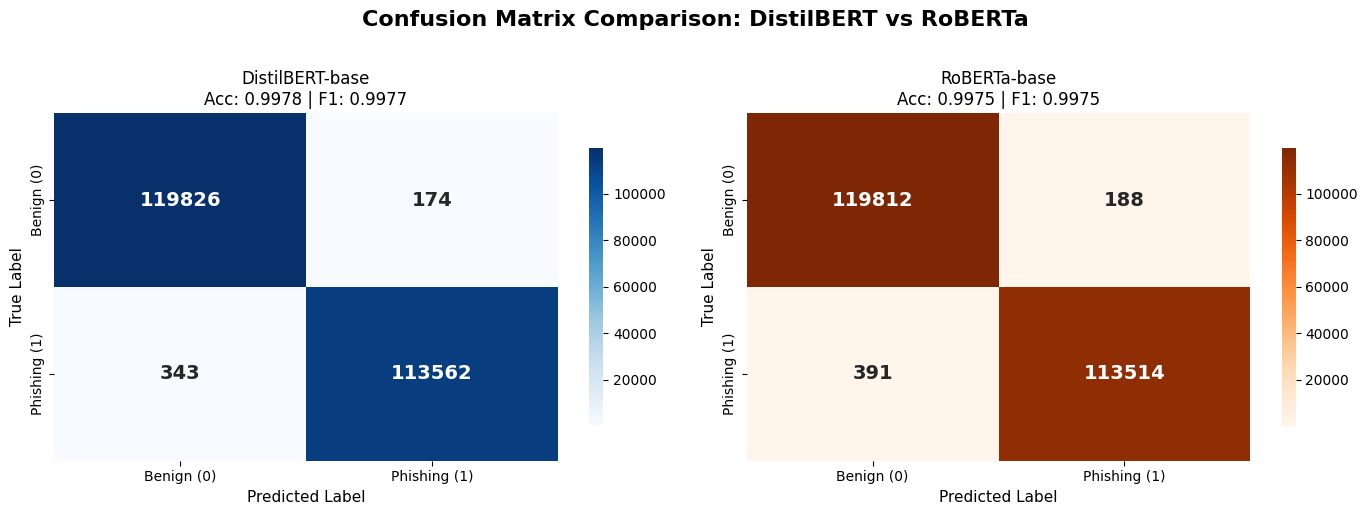

Confusion Matrix disimpan ke: /content/drive/MyDrive/Skripsi/results/confusion_matrices_comparison.png


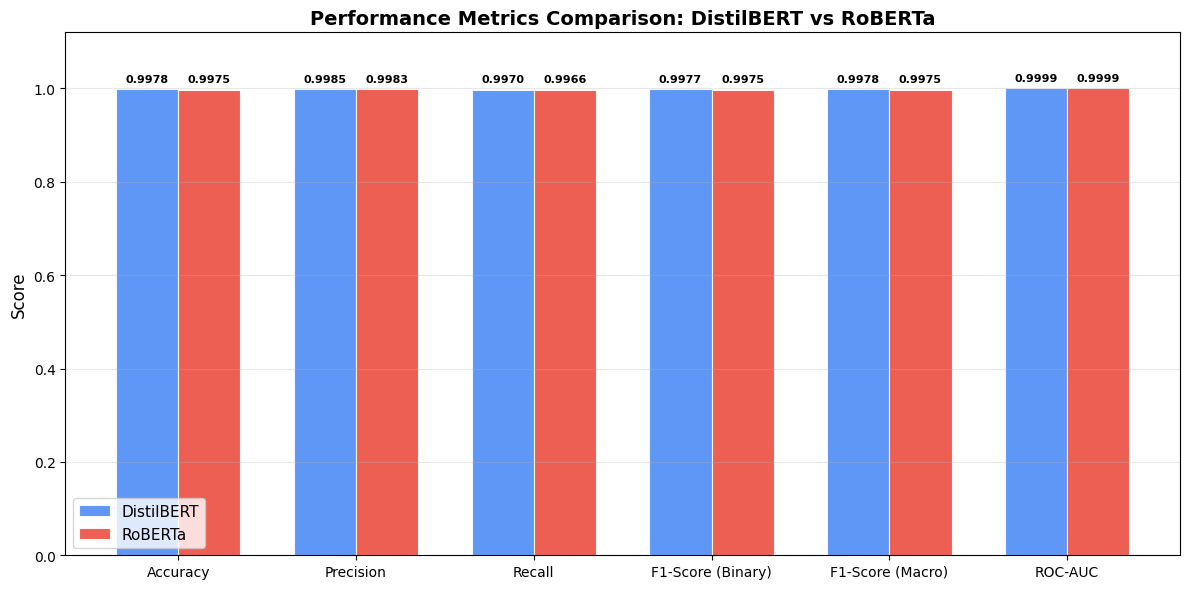

Performance chart disimpan ke: /content/drive/MyDrive/Skripsi/results/performance_metrics_comparison.png


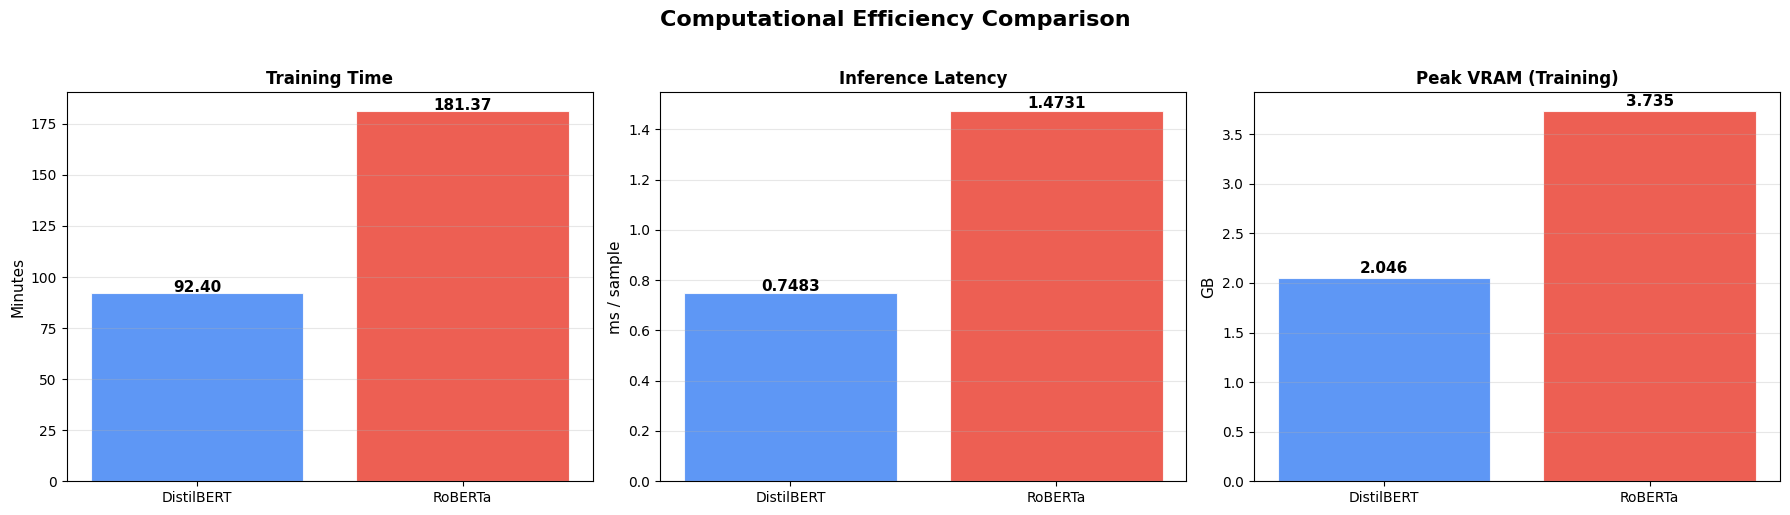

Efficiency chart disimpan ke: /content/drive/MyDrive/Skripsi/results/computational_efficiency_comparison.png

✅ Log disimpan ke: /content/drive/MyDrive/Skripsi/SKRIPSI_LOG.md

  PIPELINE SELESAI — Seluruh hasil tersimpan di Google Drive


In [13]:
# ============================================================
# Sel 13: Komparasi, Visualisasi & Ekspor CSV
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- Gabungkan hasil kedua model ---
comparison_data = []
for result in [distilbert_results, roberta_results]:
    comparison_data.append({
        'Model': result['model'],
        'Accuracy': result['accuracy'],
        'Precision': result['precision'],
        'Recall': result['recall'],
        'F1-Score (Binary)': result['f1_score'],
        'F1-Score (Macro)': result['f1_macro'],
        'ROC-AUC': result['roc_auc'],
        'Training Time (s)': result['training_time_s'],
        'Training Time (min)': result['training_time_s'] / 60,
        'Peak VRAM Training (GB)': result['peak_vram_training_gb'],
        'Total Inference Time (s)': result['total_inference_time_s'],
        'Latency per Sample (ms)': result['latency_per_sample_ms'],
        'Throughput (samples/s)': result['throughput_samples_per_s'],
        'Peak VRAM Inference (GB)': result['peak_vram_inference_gb'],
        'Total Parameters': result['total_params'],
    })

comparison_df = pd.DataFrame(comparison_data)

# --- Tampilkan Tabel ---
print("="*80)
print("  TABEL KOMPARASI: DistilBERT vs RoBERTa")
print("="*80)

# Transpose untuk tampilan vertikal yang lebih rapi
display_df = comparison_df.set_index('Model').T
print(display_df.to_string())

# --- Ekspor ke CSV ---
comparison_df.to_csv(RESULTS_CSV, index=False)
print(f"\n✅ Tabel komparasi disimpan ke: {RESULTS_CSV}")

# --- Visualisasi Confusion Matrix Side-by-Side ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Confusion Matrix Comparison: DistilBERT vs RoBERTa', fontsize=16, fontweight='bold', y=1.02)

labels_names = ['Benign (0)', 'Phishing (1)']

# DistilBERT CM
cm_distil = distilbert_results['confusion_matrix']
sns.heatmap(
    cm_distil, annot=True, fmt='d', cmap='Blues',
    xticklabels=labels_names, yticklabels=labels_names,
    ax=axes[0], cbar_kws={'shrink': 0.8},
    annot_kws={'size': 14, 'fontweight': 'bold'}
)
axes[0].set_title(f"DistilBERT-base\nAcc: {distilbert_results['accuracy']:.4f} | F1: {distilbert_results['f1_score']:.4f}", fontsize=12)
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].set_ylabel('True Label', fontsize=11)

# RoBERTa CM
cm_roberta = roberta_results['confusion_matrix']
sns.heatmap(
    cm_roberta, annot=True, fmt='d', cmap='Oranges',
    xticklabels=labels_names, yticklabels=labels_names,
    ax=axes[1], cbar_kws={'shrink': 0.8},
    annot_kws={'size': 14, 'fontweight': 'bold'}
)
axes[1].set_title(f"RoBERTa-base\nAcc: {roberta_results['accuracy']:.4f} | F1: {roberta_results['f1_score']:.4f}", fontsize=12)
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].set_ylabel('True Label', fontsize=11)

plt.tight_layout()
cm_fig_path = os.path.join(PROJECT_DIR, 'results', 'confusion_matrices_comparison.png')
plt.savefig(cm_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Confusion Matrix disimpan ke: {cm_fig_path}")

# --- Bar Chart: Metrik Performa ---
fig, ax = plt.subplots(figsize=(12, 6))
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score (Binary)', 'F1-Score (Macro)', 'ROC-AUC']
x = np.arange(len(metrics_to_plot))
width = 0.35

distil_values = [comparison_df[comparison_df['Model'] == 'DistilBERT-base-uncased'][m].values[0] for m in metrics_to_plot]
roberta_values = [comparison_df[comparison_df['Model'] == 'RoBERTa-base'][m].values[0] for m in metrics_to_plot]

bars1 = ax.bar(x - width/2, distil_values, width, label='DistilBERT', color='#4285F4', alpha=0.85, edgecolor='white', linewidth=0.8)
bars2 = ax.bar(x + width/2, roberta_values, width, label='RoBERTa', color='#EA4335', alpha=0.85, edgecolor='white', linewidth=0.8)

# Annotasi nilai di atas bar
for bar_group in [bars1, bars2]:
    for bar in bar_group:
        height = bar.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_ylabel('Score', fontsize=12)
ax.set_title('Performance Metrics Comparison: DistilBERT vs RoBERTa', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot, fontsize=10)
ax.legend(fontsize=11)
ax.set_ylim(0, 1.12)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
perf_fig_path = os.path.join(PROJECT_DIR, 'results', 'performance_metrics_comparison.png')
plt.savefig(perf_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Performance chart disimpan ke: {perf_fig_path}")

# --- Bar Chart: Efisiensi Komputasi ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Computational Efficiency Comparison', fontsize=16, fontweight='bold', y=1.02)

model_names = ['DistilBERT', 'RoBERTa']
colors = ['#4285F4', '#EA4335']

# Training Time
train_times = [distilbert_results['training_time_s']/60, roberta_results['training_time_s']/60]
bars = axes[0].bar(model_names, train_times, color=colors, alpha=0.85, edgecolor='white', linewidth=0.8)
for bar, val in zip(bars, train_times):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f'{val:.2f}', ha='center', fontweight='bold', fontsize=11)
axes[0].set_ylabel('Minutes', fontsize=11)
axes[0].set_title('Training Time', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

# Latency per Sample
latencies = [distilbert_results['latency_per_sample_ms'], roberta_results['latency_per_sample_ms']]
bars = axes[1].bar(model_names, latencies, color=colors, alpha=0.85, edgecolor='white', linewidth=0.8)
for bar, val in zip(bars, latencies):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{val:.4f}', ha='center', fontweight='bold', fontsize=11)
axes[1].set_ylabel('ms / sample', fontsize=11)
axes[1].set_title('Inference Latency', fontsize=12, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

# Peak VRAM
vrams = [distilbert_results['peak_vram_training_gb'], roberta_results['peak_vram_training_gb']]
bars = axes[2].bar(model_names, vrams, color=colors, alpha=0.85, edgecolor='white', linewidth=0.8)
for bar, val in zip(bars, vrams):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, f'{val:.3f}', ha='center', fontweight='bold', fontsize=11)
axes[2].set_ylabel('GB', fontsize=11)
axes[2].set_title('Peak VRAM (Training)', fontsize=12, fontweight='bold')
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
eff_fig_path = os.path.join(PROJECT_DIR, 'results', 'computational_efficiency_comparison.png')
plt.savefig(eff_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Efficiency chart disimpan ke: {eff_fig_path}")

# --- Ringkasan Log ke SKRIPSI_LOG.md ---
log_content = f"""# SKRIPSI LOG - Hasil Komparasi DistilBERT vs RoBERTa

**Tanggal Eksekusi**: {time.strftime('%Y-%m-%d %H:%M:%S')}
**Hyperparameters**: SEED={SEED}, MAX_LENGTH={MAX_LENGTH}, BATCH_SIZE={BATCH_SIZE}
**1-Stage Fine-Tuning**: Epochs={EPOCHS}, LR={LEARNING_RATE}, Warmup={WARMUP_RATIO*100:.0f}%, WeightDecay={WEIGHT_DECAY}
**Dataset**: vonDataset_clean.csv ({len(train_df)+len(val_df)+len(test_df):,} total samples)
**Split**: Train={len(train_df):,} | Val={len(val_df):,} | Test={len(test_df):,}

## Hasil Evaluasi pada Test Set

| Metrik | DistilBERT | RoBERTa |
|--------|-----------|----------|
| Accuracy | {distilbert_results['accuracy']:.6f} | {roberta_results['accuracy']:.6f} |
| Precision | {distilbert_results['precision']:.6f} | {roberta_results['precision']:.6f} |
| Recall | {distilbert_results['recall']:.6f} | {roberta_results['recall']:.6f} |
| F1-Score | {distilbert_results['f1_score']:.6f} | {roberta_results['f1_score']:.6f} |
| F1-Macro | {distilbert_results['f1_macro']:.6f} | {roberta_results['f1_macro']:.6f} |
| ROC-AUC | {distilbert_results['roc_auc']:.6f} | {roberta_results['roc_auc']:.6f} |
| Training Time (min) | {distilbert_results['training_time_s']/60:.2f} | {roberta_results['training_time_s']/60:.2f} |
| Peak VRAM Train (GB) | {distilbert_results['peak_vram_training_gb']:.3f} | {roberta_results['peak_vram_training_gb']:.3f} |
| Latency (ms/sample) | {distilbert_results['latency_per_sample_ms']:.4f} | {roberta_results['latency_per_sample_ms']:.4f} |
| Throughput (samples/s) | {distilbert_results['throughput_samples_per_s']:.2f} | {roberta_results['throughput_samples_per_s']:.2f} |
| Total Parameters | {distilbert_results['total_params']:,} | {roberta_results['total_params']:,} |
"""

with open(LOG_FILE, 'w', encoding='utf-8') as f:
    f.write(log_content)
print(f"\n✅ Log disimpan ke: {LOG_FILE}")

print("\n" + "="*80)
print("  PIPELINE SELESAI — Seluruh hasil tersimpan di Google Drive")
print("="*80)

In [14]:
# ============================================================
# Sel 14: Verifikasi Penyimpanan Model & Tokenizer di Google Drive
# ============================================================
import os

# Direktori tujuan model di Google Drive
MODELS_DIR = '/content/drive/MyDrive/Skripsi/models'
DISTILBERT_SAVE_PATH = os.path.join(MODELS_DIR, 'distilbert_phishing')
ROBERTA_SAVE_PATH = os.path.join(MODELS_DIR, 'roberta_phishing')

print("=" * 70)
print("  VERIFIKASI FILE MODEL & TOKENIZER DI GOOGLE DRIVE")
print("=" * 70)

# Fallback: Simpan jika model masih ada di memori
if 'distil_model' in globals():
    print("Menyimpan DistilBERT dari memori aktif...")
    distil_model.save_pretrained(DISTILBERT_SAVE_PATH)
    tokenizer.save_pretrained(DISTILBERT_SAVE_PATH)

if 'roberta_model' in globals():
    print("Menyimpan RoBERTa dari memori aktif...")
    roberta_model.save_pretrained(ROBERTA_SAVE_PATH)
    tokenizer.save_pretrained(ROBERTA_SAVE_PATH)

# Verifikasi keberadaan file di Google Drive
for model_name, path in [('DistilBERT', DISTILBERT_SAVE_PATH), ('RoBERTa', ROBERTA_SAVE_PATH)]:
    print(f"\nMemeriksa direktori {model_name}: {path}")
    if os.path.exists(path):
        files = os.listdir(path)
        print(f"  Status: Direktori ditemukan ({len(files)} file)")
        for f in sorted(files):
            fpath = os.path.join(path, f)
            fsize_mb = os.path.getsize(fpath) / (1024 * 1024)
            print(f"    - {f} ({fsize_mb:.2f} MB)")
        
        has_config = any('config' in f for f in files)
        has_weights = any('model' in f or 'pytorch' in f or 'safetensors' in f for f in files)
        if has_config and has_weights:
            print(f"  ✅ {model_name} tersimpan lengkap (config & bobot model valid).")
        else:
            print(f"  ⚠️ File {model_name} mungkin belum lengkap, periksa file bobot.")
    else:
        print(f"  ❌ Direktori belum ditemukan: {path}")

print("\n" + "=" * 70)
print("  Verifikasi penyimpanan model ke Google Drive selesai.")
print("=" * 70)


  VERIFIKASI FILE MODEL & TOKENIZER DI GOOGLE DRIVE

Memeriksa direktori DistilBERT: /content/drive/MyDrive/Skripsi/models/distilbert_phishing
  Status: Direktori ditemukan (4 file)
    - config.json (0.00 MB)
    - model.safetensors (254.99 MB)
    - tokenizer.json (0.67 MB)
    - tokenizer_config.json (0.00 MB)
  ✅ DistilBERT tersimpan lengkap (config & bobot model valid).

Memeriksa direktori RoBERTa: /content/drive/MyDrive/Skripsi/models/roberta_phishing
  Status: Direktori ditemukan (4 file)
    - config.json (0.00 MB)
    - model.safetensors (417.23 MB)
    - tokenizer.json (0.67 MB)
    - tokenizer_config.json (0.00 MB)
  ✅ RoBERTa tersimpan lengkap (config & bobot model valid).

  Verifikasi penyimpanan model ke Google Drive selesai.
